**Nome:** Salvador Franco Sequeira · **Número:** 53912

**Nome:** Ricardo Costa · **Número:** 53732

**Data:** 12/11/2026

# Projeto Final · LusoEnergia
## Parte I - Fundação (Checkpoint 1)

Para o Checkpoint 1: dados carregados e tipados (1.1) e auditoria de qualidade esboçada (1.2). O sumário estatístico (1.3) fica para o Checkpoint 2.

# Preparação

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from math import comb

from src.dados import (FICHEIRO, carregar_dados, recortar, validar, janela_do_grupo,
                       lacunas, tratar_lacunas, consumo_diario)

NUMEROS = [53912, 53732]
SEED = sum(NUMEROS)
JANELA = janela_do_grupo(SEED)
inicio, fim = JANELA
DIAS = ['segunda', 'terça', 'quarta', 'quinta', 'sexta', 'sábado', 'domingo']

print(f'Seed = {SEED}')
print(f'Janela: {inicio:%d/%m/%Y} a {fim - pd.Timedelta(minutes=1):%d/%m/%Y %H:%M} ({fim:%d/%m/%Y} já fica de fora)')

Seed = 107644
Janela: 01/02/2008 a 31/07/2009 23:59 (01/08/2009 já fica de fora)


R.: A janela do grupo vai de 1 de fevereiro de 2008 a 31 de julho de 2009: 547 dias, 787 680 minutos. Tratamos a janela como intervalo semiaberto [início, fim), para ter exatamente 18 meses sem o primeiro minuto de agosto. A janela cobre um inverno completo (2008/09) e o fim de outro (fevereiro de 2008), o verão de 2008 e junho e julho de 2009. Os meses de fevereiro a julho aparecem duas vezes e os de agosto a janeiro só uma, o que convém lembrar quando se falar de sazonalidade anual, sobretudo em agosto, o mês típico de férias em França.

# 1.1 Carregamento e tipagem

**1.1)** Construir uma função `carregar_dados()` que lê o ficheiro bruto e devolve um DataFrame com índice temporal (`DatetimeIndex`), dtypes justificados variável a variável (dicionário de dados com a escala de medida de Stevens de cada coluna) e sentinelas `'?'` convertidas. Mínimo de 5 asserts de validação.

In [2]:
# a) O ficheiro bruto

with open(FICHEIRO, encoding='utf-8') as f:
    print(''.join(next(f) for _ in range(3)))

with open(FICHEIRO, encoding='utf-8') as f:
    falhas = [linha for linha in f if '?' in linha]

print(falhas[0])
print(f'Linhas com "?": {len(falhas)}')

Date;Time;Global_active_power;Global_reactive_power;Voltage;Global_intensity;Sub_metering_1;Sub_metering_2;Sub_metering_3
16/12/2006;17:24:00;4.216;0.418;234.840;18.400;0.000;1.000;17.000
16/12/2006;17:25:00;5.360;0.436;233.630;23.000;0.000;1.000;16.000



21/12/2006;11:23:00;?;?;?;?;?;?;

Linhas com "?": 25979


R.: O ficheiro tem extensão .csv, mas o separador é `;`. A data e a hora vêm em duas colunas de texto, com a data no formato dia/mês/ano: sem `format` explícito, o pandas pode ler 1/2/2007 como 2 de janeiro. As leituras em falta têm `?` em seis colunas, mas a última (Sub_metering_3) vem vazia, por isso há duas sentinelas: `?` e o campo vazio. São 25 979 linhas de falha.

In [3]:
# b) Carregamento

%time completo = carregar_dados()
df = recortar(completo, JANELA)

print(f'Completo: {len(completo)} linhas, de {completo.index[0]} a {completo.index[-1]}')
print(f'Janela:   {len(df)} linhas, de {df.index[0]} a {df.index[-1]}')
print(f'Linhas sem leitura no completo: {completo.isna().all(axis=1).sum()} (linhas com "?" no bruto: {len(falhas)})')
print()
df.info()

memoria = pd.Series({'float32': completo.memory_usage(deep=True).sum(),
                     'float64': completo.astype('float64').memory_usage(deep=True).sum()}) / 1e6
print()
print('Memória do conjunto completo (MB):', memoria.round(1).to_dict())

CPU times: total: 9.2 s
Wall time: 9.43 s


Completo: 2075259 linhas, de 2006-12-16 17:24:00 a 2010-11-26 21:02:00
Janela:   787680 linhas, de 2008-02-01 00:00:00 a 2009-07-31 23:59:00
Linhas sem leitura no completo: 25979 (linhas com "?" no bruto: 25979)

<class 'pandas.DataFrame'>
DatetimeIndex: 787680 entries, 2008-02-01 00:00:00 to 2009-07-31 23:59:00
Data columns (total 7 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Global_active_power    784164 non-null  float32
 1   Global_reactive_power  784164 non-null  float32
 2   Voltage                784164 non-null  float32
 3   Global_intensity       784164 non-null  float32
 4   Sub_metering_1         784164 non-null  float32
 5   Sub_metering_2         784164 non-null  float32
 6   Sub_metering_3         784164 non-null  float32
dtypes: float32(7)
memory usage: 27.0 MB

Memória do conjunto completo (MB): {'float32': 74.7, 'float64': 132.8}


R.: A função `carregar_dados()` está em `src/dados.py`, porque vai ser usada em todas as partes e no dashboard. Faz três coisas:

1. Lê o ficheiro com `sep=';'`, `na_values=['?', '']` e `keep_default_na=False`: só estes dois códigos passam a NaN. As 7 colunas numéricas são lidas diretamente como float32, por isso qualquer outro texto inesperado faria o `read_csv` falhar, em vez de deixar a coluna como texto sem avisar.
2. Constrói o índice com `to_datetime(Date, format='%d/%m/%Y') + to_timedelta(Time)`, vetorizado e com o formato explícito.
3. Chama `validar(df)`, que corre os asserts (ver d). `recortar()` volta a validar depois de cortar a janela.

As 25 979 linhas com `?` no ficheiro bruto são exatamente as 25 979 linhas sem leitura no DataFrame, por isso todas as sentinelas foram convertidas. A leitura completa demora menos de meio minuto; ponderámos guardar um parquet intermédio, como sugere o enunciado, mas com este tempo não compensa o risco de trabalhar com uma cópia desatualizada. O ficheiro bruto fica intocado e é sempre a fonte.

In [4]:
# c) Dicionário de dados

dicionario = pd.DataFrame([
    ('instante (índice)', 'data e hora da leitura (Date + Time)', '-', 'intervalar', 'datetime64[us]',
     'permite resample, janelas e filtros por data; sem fuso horário (ver e)'),
    ('Global_active_power', 'potência ativa média no minuto', 'kW', 'razão', 'float32',
     'contínua, 3 casas decimais: os 7 algarismos significativos do float32 chegam'),
    ('Global_reactive_power', 'potência reativa média no minuto', 'kW (rigorosamente kvar)', 'razão', 'float32',
     'contínua, 3 casas decimais; muitas leituras a 0'),
    ('Voltage', 'tensão média no minuto', 'V', 'razão', 'float32',
     'contínua, 2 casas decimais'),
    ('Global_intensity', 'intensidade de corrente média no minuto', 'A', 'razão', 'float32',
     'múltiplos de 0,2 A (resolução do aparelho)'),
    ('Sub_metering_1', 'energia ativa da cozinha (máq. loiça, forno, micro-ondas)', 'Wh no minuto', 'razão', 'float32',
     'contador inteiro; float32 e não Int16 porque tem NaN (ver R.)'),
    ('Sub_metering_2', 'energia ativa da lavandaria (máq. roupa, secador, frigorífico, luz)', 'Wh no minuto', 'razão', 'float32',
     'idem'),
    ('Sub_metering_3', 'energia ativa do termoacumulador e do ar condicionado', 'Wh no minuto', 'razão', 'float32',
     'idem'),
], columns=['variavel', 'descricao', 'unidade', 'escala_Stevens', 'dtype', 'justificacao']).set_index('variavel')

estatisticas = completo.agg(['min', 'max']).T.round(3)
estatisticas['distintos'] = completo.nunique()
estatisticas['%_zeros'] = (100 * (completo == 0).mean()).round(1)
dicionario.join(estatisticas)

,descricao,unidade,escala_Stevens,dtype,justificacao,min,max,distintos,%_zeros
variavel,,,,,,,,,
instante (índice),data e hora da leitura (Date + Time),-,intervalar,datetime64[us],"permite resample, janelas e filtros por data; ...",NaN,NaN,NaN,NaN
Global_active_power,potência ativa média no minuto,kW,razão,float32,"contínua, 3 casas decimais: os 7 algarismos si...",0.076000,11.122000,4186.0,0.0
Global_reactive_power,potência reativa média no minuto,kW (rigorosamente kvar),razão,float32,"contínua, 3 casas decimais; muitas leituras a 0",0.000000,1.390000,532.0,23.2
Voltage,tensão média no minuto,V,razão,float32,"contínua, 2 casas decimais",223.199997,254.149994,2837.0,0.0
Global_intensity,intensidade de corrente média no minuto,A,razão,float32,"múltiplos de 0,2 A (resolução do aparelho)",0.200000,48.400002,221.0,0.0
Sub_metering_1,"energia ativa da cozinha (máq. loiça, forno, m...",Wh no minuto,razão,float32,contador inteiro; float32 e não Int16 porque t...,0.000000,88.000000,88.0,90.6
Sub_metering_2,"energia ativa da lavandaria (máq. roupa, secad...",Wh no minuto,razão,float32,idem,0.000000,80.000000,81.0,69.2
Sub_metering_3,energia ativa do termoacumulador e do ar condi...,Wh no minuto,razão,float32,idem,0.000000,31.000000,32.0,41.1


R.: Todas as variáveis numéricas são de razão: têm um zero com significado físico (sem potência, sem corrente, sem energia) e faz sentido dizer que um valor é o dobro de outro. A tensão é um caso-limite: o zero existe fisicamente, mas os valores vivem numa banda estreita (223 a 254 V) à volta do nominal, e o que interessa são os desvios, não as razões. O índice é intervalar: a origem do calendário é convencional, por isso a diferença entre dois instantes tem significado, mas a razão não.

As unidades exigem atenção: a potência é uma média no minuto em kW e as submedições são energia em Wh nesse minuto. A ponte é energia (Wh) = potência (kW) × 1000 / 60, e o consumo diário em kWh é a média da potência no dia × 24 h. Esquecer a divisão por 60 multiplica a energia por 60; confundir W com kW, por 1000.

Escolhemos float32 em vez do float64 por omissão: os dados têm no máximo três casas decimais em valores abaixo de 260, muito dentro dos 7 algarismos significativos do float32, e a memória do conjunto completo cai de 132,8 para 74,7 MB. O custo é que somas sobre centenas de milhares de minutos acumulam erro de arredondamento em float32, por isso as agregações convertem primeiro para float64: já o fazemos em `consumo_diario()` e vamos fazê-lo na verificação do Welford na Parte IV. As submedições são inteiras, mas guardá-las como `Int16` (inteiro com NA) pouparia pouca memória (3 bytes por valor, contando a máscara de NA, contra 4) e obrigaria a converter o `pd.NA` sempre que passassem por numpy, sklearn ou river; o float32 representa exatamente todos os inteiros até 16 milhões.

**d) Asserts de validação** (em `validar()`, chamada por `carregar_dados()` e `recortar()`)

| # | Assert | Porquê |
|---|---|---|
| 1 | o índice é `DatetimeIndex` | resample, janelas e filtros por data dependem dele |
| 2 | índice único e ordenado | instantes repetidos contariam consumo duas vezes; fora de ordem estragam as janelas deslizantes e o replay da Parte IV |
| 3 | passos de exatamente 1 minuto | cada falha é uma linha NaN visível, e não um minuto que simplesmente não existe |
| 4 | todas as variáveis em float32 | confirma que nenhuma coluna ficou como texto por causa das sentinelas |
| 5 | falta tudo ou nada em cada linha | a falha é do registo e não de um sensor; é a base do argumento sobre o mecanismo em 1.2 |
| 6 | potências, intensidade e energias ≥ 0 | uma casa só consome; um negativo seria erro de leitura ou de sinal |
| 7 | tensão entre 200 e 260 V | rede de 230 V; fora disto a unidade está errada (kV, mV) ou há colunas trocadas |
| 8 | submedições inteiras | são contadores em Wh; decimais indicariam outra unidade |
| 9 | soma das submedições ≤ energia total do minuto + 3 Wh | uma parte da casa não pode gastar mais do que a casa toda; os 3 Wh cobrem o arredondamento dos três contadores inteiros (até 1 Wh cada) |
| 10 | I ≈ √(P² + Q²) × 1000 / V, com erro mediano < 0,2 A | confirma as unidades kW, V e A em conjunto: com a potência em W o erro seria mil vezes maior |

Os dados reais passam os 10 (a célula de carregamento correu sem erro). Para mostrar que os asserts não passam tudo, damos-lhes versões estragadas de propósito:

In [5]:
# d) Os asserts apanham erros?

estragados = {
    'tensão em kV': df.assign(Voltage=df['Voltage'] / 1000),
    'potência em W': df.assign(Global_active_power=df['Global_active_power'] * 1000),
    'minuto repetido': pd.concat([df.iloc[:1], df]),
    'minuto sem linha': df.drop(df.index[100]),
    'falta parcial': df.assign(Voltage=df['Voltage'].where(df.index != df.index[0])),
}

for nome, versao in estragados.items():
    try:
        validar(versao)
        print(f'{nome:17} -> passou sem erro')
    except AssertionError as erro:
        print(f'{nome:17} -> apanhado: {erro}')

tensão em kV      -> apanhado: tensão fora de 200 a 260 V (unidade errada?)


potência em W     -> apanhado: I diferente de S/V: unidades incoerentes
minuto repetido   -> apanhado: índice com instantes repetidos ou fora de ordem
minuto sem linha  -> apanhado: grelha de 1 min com buracos: há minutos sem linha
falta parcial     -> apanhado: linha com falta parcial (esperado: tudo ou nada)


R.: As cinco versões estragadas são todas apanhadas, cada uma pelo assert correspondente. A potência em W passa os testes de sinal e de balanço de energia: o balanço (assert 9) só limita as submedições por cima, e uma potência mil vezes maior continua a respeitá-lo. Só a coerência I = S/V (assert 10) a apanha.

In [6]:
# e) O relógio muda de hora?

mudancas_hora = pd.to_datetime(['2008-03-30', '2008-10-26', '2009-03-29'])
df.groupby(df.index.normalize()).size().loc[mudancas_hora].to_frame('minutos_no_dia')

,minutos_no_dia
2008-03-30,1440
2008-10-26,1440
2009-03-29,1440


R.: Nos três dias de mudança de hora da janela há exatamente 1440 minutos, e não 1380 ou 1500, e o assert 3 garante o mesmo nos quatro anos. O relógio do registador não segue a hora legal de verão, por isso deixamos o índice sem fuso horário (tz-naive). Isto tem uma consequência para a Parte II: não sabemos em que fuso está o relógio, e no verão a hora registada pode estar desfasada uma hora da hora legal francesa. Um pico às 7 h no verão pode ser às 8 h na vida da família.

# 1.2 Auditoria de qualidade (esboço)

**1.2)** Quantificar os valores em falta por variável e por período (encontrar os dias inteiros sem leituras e visualizá-los num calendário), classificar o mecanismo provável (MCAR/MAR/MNAR) com argumentação e justificar a estratégia de tratamento, que tem de ser diferente para lacunas de 1 minuto e de 2 dias.

In [7]:
# a) Falta por variável

falta = pd.DataFrame({'completo': completo.isna().sum(), 'janela': df.isna().sum()})
falta['completo_%'] = (100 * falta['completo'] / len(completo)).round(2)
falta['janela_%'] = (100 * falta['janela'] / len(df)).round(2)
falta

,completo,janela,completo_%,janela_%
Global_active_power,25979,3516,1.25,0.45
Global_reactive_power,25979,3516,1.25,0.45
Voltage,25979,3516,1.25,0.45
Global_intensity,25979,3516,1.25,0.45
Sub_metering_1,25979,3516,1.25,0.45
Sub_metering_2,25979,3516,1.25,0.45
Sub_metering_3,25979,3516,1.25,0.45


R.: As sete variáveis têm exatamente o mesmo número de valores em falta: 25 979 minutos (1,25 %) no conjunto completo e 3 516 (0,45 %) na nossa janela. Com o assert 5, isto mostra que não há falhas de um sensor isolado: quando falta, falta a linha inteira. A auditoria por variável esgota-se aqui e o resto é sobre o tempo. A nossa janela é relativamente limpa: tem pouco mais de um terço da taxa de falta do conjunto completo.

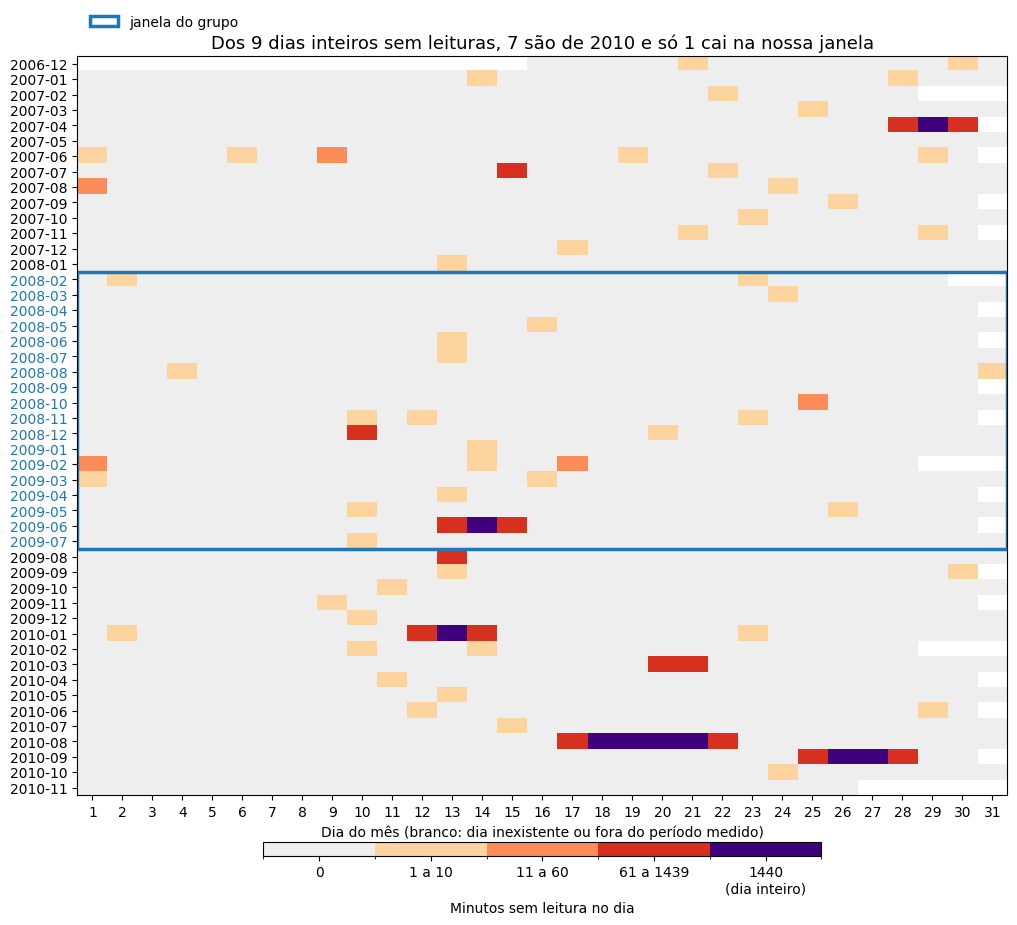

In [8]:
# b) Falta por período: calendário

minutos_falta = completo['Global_active_power'].isna().resample('D').sum()
calendario = (minutos_falta.to_frame('minutos')
              .assign(mes=lambda d: d.index.strftime('%Y-%m'), dia=lambda d: d.index.day)
              .pivot(index='mes', columns='dia', values='minutos'))

limites = [-0.5, 0.5, 10.5, 60.5, 1439.5, 1440.5]
classes = ['0', '1 a 10', '11 a 60', '61 a 1439', '1440\n(dia inteiro)']
cores = ListedColormap(['#eeeeee', '#fdd49e', '#fc8d59', '#d7301f', '#3f007d'])
meses_janela = np.flatnonzero((calendario.index >= f'{inicio:%Y-%m}') & (calendario.index < f'{fim:%Y-%m}'))

fig, ax = plt.subplots(figsize=(12, 12))
im = ax.imshow(calendario, cmap=cores, norm=BoundaryNorm(limites, cores.N), aspect='auto')
moldura = Rectangle((-0.5, meses_janela[0] - 0.5), 31, len(meses_janela),
                    fill=False, edgecolor='tab:blue', lw=2.5, label='janela do grupo')
ax.add_patch(moldura)
ax.set_xticks(range(31), range(1, 32))
ax.set_yticks(range(len(calendario)), calendario.index)
for i in meses_janela:
    ax.get_yticklabels()[i].set_color('tab:blue')
ax.set_xlabel('Dia do mês (branco: dia inexistente ou fora do período medido)')
ax.set_title('Dos 9 dias inteiros sem leituras, 7 são de 2010 e só 1 cai na nossa janela', fontsize=13)
ax.legend(handles=[moldura], loc='lower left', bbox_to_anchor=(0, 1.02), frameon=False)
barra = fig.colorbar(im, ax=ax, location='bottom', ticks=[0, 5.5, 35.5, 750, 1440], shrink=0.6, aspect=40, pad=0.05)
barra.set_ticklabels(classes)
barra.set_label('Minutos sem leitura no dia')
plt.show()

In [9]:
dias_sem_leitura = minutos_falta[minutos_falta == 1440].to_frame('minutos')
dias_sem_leitura['dia_semana'] = [DIAS[d] for d in dias_sem_leitura.index.dayofweek]
dias_sem_leitura['na_janela'] = (dias_sem_leitura.index >= inicio) & (dias_sem_leitura.index < fim)
display(dias_sem_leitura)

falhas_longas = lacunas(completo).query('minutos >= 1440').assign(dias=lambda d: (d['minutos'] / 1440).round(1))
display(falhas_longas)

por_mes = (100 * df['Global_active_power'].isna().resample('MS').mean()).round(2)
por_mes.index = por_mes.index.strftime('%Y-%m')
por_mes.to_frame('% em falta').T

,minutos,dia_semana,na_janela
instante,,,
2007-04-29,1440,domingo,False
2009-06-14,1440,domingo,True
2010-01-13,1440,quarta,False
2010-08-18,1440,quarta,False
2010-08-19,1440,quinta,False
2010-08-20,1440,sexta,False
2010-08-21,1440,sábado,False
2010-09-26,1440,domingo,False
2010-09-27,1440,segunda,False


,inicio,fim,minutos,dias
6,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,2.6
49,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,2.3
58,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,2.2
62,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,1.4
68,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,5.0
69,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,3.6


instante,2008-02,2008-03,2008-04,2008-05,2008-06,2008-07,2008-08,2008-09,2008-10,2008-11,2008-12,2009-01,2009-02,2009-03,2009-04,2009-05,2009-06,2009-07
% em falta,0.01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.02,0.16,0.0,0.16,0.0,0.0,0.01,7.65,0.01


R.: No conjunto completo há 9 dias inteiros sem leituras, 7 deles em 2010 (incluindo 4 seguidos em agosto). Há 6 falhas de mais de 1 dia, e os 9 dias inteiros caem nas 5 que duram mais de 2 dias (de 2,2 a 5 dias). Na nossa janela só há um, domingo 14 de junho de 2009, no meio da única falha longa, que vai de sábado 13/06 às 00:30 a segunda 15/06 às 07:34. Por isso junho de 2009 tem 7,7 % dos minutos em falta e todos os outros meses estão abaixo de 0,2 %. O calendário mostra também que as falhas curtas (laranja claro) estão espalhadas pelos quatro anos, sem se concentrarem num período.

In [10]:
# c) Lacunas na janela: quantas e de que tamanho

lac = lacunas(df)
lac['dia_semana'] = [DIAS[d] for d in lac['inicio'].dt.dayofweek]
lac['classe'] = pd.cut(lac['minutos'], [0, 1, 10, 60, 1440, np.inf],
                       labels=['1 min', '2 a 10 min', '11 a 60 min', '1 h a 1 dia', 'mais de 1 dia'])

resumo = lac.groupby('classe', observed=False)['minutos'].agg(lacunas='size', minutos='sum')
resumo['%_dos_minutos'] = (100 * resumo['minutos'] / resumo['minutos'].sum()).round(1)
display(resumo)
lac[lac['minutos'] > 10]

,lacunas,minutos,%_dos_minutos
classe,,,
1 min,11,11,0.3
2 a 10 min,9,25,0.7
11 a 60 min,3,105,3.0
1 h a 1 dia,1,70,2.0
mais de 1 dia,1,3305,94.0


,inicio,fim,minutos,dia_semana,classe
8,2008-10-25 10:28:00,2008-10-25 11:10:00,43,sábado,11 a 60 min
12,2008-12-10 10:48:00,2008-12-10 11:57:00,70,quarta,1 h a 1 dia
15,2009-02-01 16:29:00,2009-02-01 17:06:00,38,domingo,11 a 60 min
17,2009-02-17 10:06:00,2009-02-17 10:29:00,24,terça,11 a 60 min
23,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,sábado,mais de 1 dia


R.: Há 25 lacunas na janela, com durações muito diferentes. 20 duram 10 minutos ou menos (11 delas um só minuto) e somam 36 minutos, 1 % do que falta. No outro extremo, uma única lacuna de 3 305 minutos (2,3 dias) vale 94 % de todos os minutos em falta. Pelo meio ficam 4 lacunas de 24 a 70 minutos, todas de dia, entre as 10 h e as 17 h. A duração média de uma lacuna (141 min) não descreve nenhuma delas; o que conta é a distribuição.

**d) Mecanismo provável**

Há três factos já estabelecidos: a falta é sempre da linha inteira, por isso é uma falha do registo ou da comunicação e não de um sensor; as lacunas curtas espalham-se pelos quatro anos, sem se concentrarem num período (calendário); e a falha longa coincide com um fim de semana. Abaixo testamos duas coisas: se as lacunas curtas acontecem em momentos de consumo especial, e o que se passa à volta da falha longa.

In [11]:
# d) Lacunas curtas: acontecem em momentos de consumo especial?

potencia = df['Global_active_power']
media_hora = potencia.groupby(potencia.index.hour).mean()
curtas = lac[lac['minutos'] < 1440]

antes = pd.DataFrame({'antes_kW': potencia.shift(1).loc[curtas['inicio']].to_numpy(),
                      'media_da_hora_kW': media_hora.loc[curtas['inicio'].dt.hour].to_numpy()})
antes['razao'] = antes['antes_kW'] / antes['media_da_hora_kW']

n, k, p = len(antes), (antes['antes_kW'] > 3).sum(), (potencia > 3).mean()
p_valor = sum(comb(n, i) * p**i * (1 - p)**(n - i) for i in range(k, n + 1))

print(f"Mediana da razão (minuto antes da lacuna / média dessa hora): {antes['razao'].median():.2f}")
print(f'Lacunas que começam a seguir a um minuto acima de 3 kW: {k} de {n} (por acaso esperaríamos {n * p:.1f})')
print(f'Minutos acima de 3 kW na janela: {p:.1%} | P(X >= {k}) numa binomial(n={n}, p={p:.3f}) = {p_valor:.3f}')
print(f'Autocorrelação da potência a 1 minuto: {potencia.autocorr(1):.2f}')

Mediana da razão (minuto antes da lacuna / média dessa hora): 1.08
Lacunas que começam a seguir a um minuto acima de 3 kW: 5 de 24 (por acaso esperaríamos 1.3)
Minutos acima de 3 kW na janela: 5.5% | P(X >= 5) numa binomial(n=24, p=0.055) = 0.009
Autocorrelação da potência a 1 minuto: 0.97


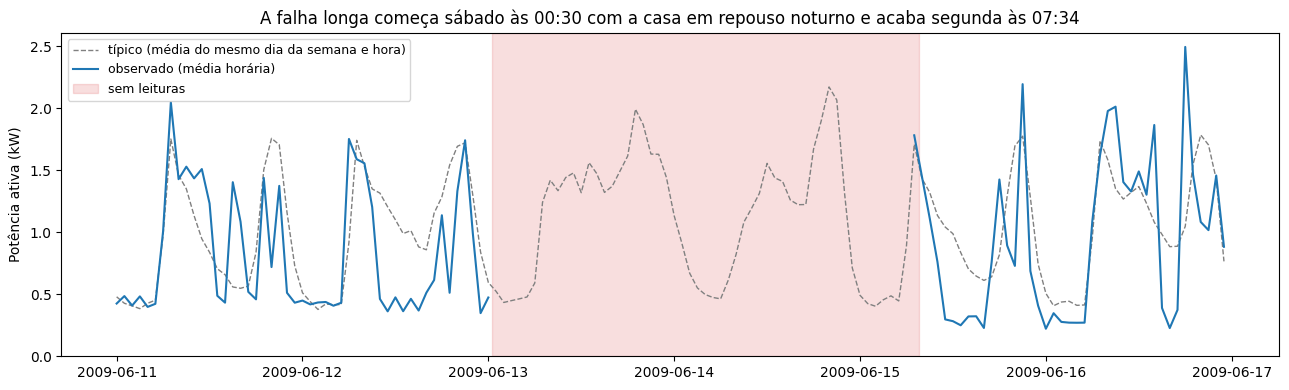

Últimos minutos antes da falha:
                     Global_active_power     Voltage  Sub_metering_3
instante                                                            
2009-06-13 00:25:00                0.322  241.309998             0.0
2009-06-13 00:26:00                0.340  241.380005             1.0
2009-06-13 00:27:00                0.338  241.589996             1.0
2009-06-13 00:28:00                0.340  241.559998             0.0
2009-06-13 00:29:00                0.340  241.399994             1.0

Primeiros minutos depois da falha:
                     Global_active_power     Voltage  Sub_metering_3
instante                                                            
2009-06-15 07:35:00                2.162  238.520004            25.0
2009-06-15 07:36:00                2.222  238.330002            29.0
2009-06-15 07:37:00                2.234  237.199997            29.0
2009-06-15 07:38:00                2.224  235.940002            29.0
2009-06-15 07:39:00                

In [12]:
# d) A falha longa (13 a 15/06/2009)

longa = lac.loc[lac['minutos'].idxmax()]
tipico = potencia.groupby([potencia.index.dayofweek, potencia.index.hour]).mean()
zoom = potencia.loc['2009-06-11':'2009-06-16'].resample('h').mean().to_frame('observado')
zoom['tipico'] = tipico.loc[list(zip(zoom.index.dayofweek, zoom.index.hour))].to_numpy()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(zoom.index, zoom['tipico'], color='gray', ls='--', lw=1, label='típico (média do mesmo dia da semana e hora)')
ax.plot(zoom.index, zoom['observado'], color='tab:blue', label='observado (média horária)')
ax.axvspan(longa['inicio'], longa['fim'], color='tab:red', alpha=0.15, label='sem leituras')
ax.set_ylim(bottom=0)
ax.set_ylabel('Potência ativa (kW)')
ax.set_title('A falha longa começa sábado às 00:30 com a casa em repouso noturno e acaba segunda às 07:34')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

vizinhanca = ['Global_active_power', 'Voltage', 'Sub_metering_3']
print('Últimos minutos antes da falha:')
print(df.loc[longa['inicio'] - pd.Timedelta(minutes=5):longa['inicio'], vizinhanca].dropna().to_string())
print('\nPrimeiros minutos depois da falha:')
print(df.loc[longa['fim']:longa['fim'] + pd.Timedelta(minutes=5), vizinhanca].dropna().to_string())

segundas = df[df.index.dayofweek == 0].between_time('07:35', '07:44')['Sub_metering_3']
print(f'\nSub_metering_3 numa segunda-feira típica, 07:35 a 07:44: {segundas.mean():.1f} Wh/min')
print(f"Minutos da janela com Sub_metering_3 >= 25 Wh: {(df['Sub_metering_3'] >= 25).mean():.1%}")

R.: **Lacunas curtas (menos de 1 dia).** Na mediana, o minuto anterior à lacuna tem o consumo normal para aquela hora (razão de 1,08), o que é compatível com MCAR: uma falha de comunicação ao acaso. Mas 5 das 24 começam logo a seguir a um minuto acima de 3 kW, quando por acaso esperaríamos 1,3 (p = 0,009 numa binomial). Este p é otimista: escolhemos o limiar de 3 kW depois de olhar para os dados, e com 24 lacunas basta uma ou duas para mudar o resultado. É um indício, não uma conclusão, de que o registo falha mais em picos de carga. Se se confirmar, a falta depende de um valor observado (o minuto anterior), o que é MAR e não MCAR puro; e como o consumo ao minuto tem autocorrelação de 0,97, o valor em falta é provavelmente também alto. Para o tratamento isto pesa pouco, porque a interpolação usa precisamente os vizinhos, que já refletem esse pico. Para o CP2: repetir o teste, com o limiar fixado agora, nas lacunas fora da nossa janela, que não usámos para formular a hipótese.

**Falha longa (13 a 15/06/2009).** Não temos o consumo durante a falha, e as hipóteses levam a mecanismos diferentes:

- avaria do registador com a casa a funcionar normalmente: a falta não depende do consumo (MCAR em relação ao valor);
- família fora no fim de semana com o quadro desligado, ou corte de energia: o consumo em falta seria perto de zero, e a falta depende do próprio valor não observado (MNAR).

Os dados à volta não decidem. Antes da falha, a casa está no nível de repouso noturno (0,34 kW) e a tensão é normal (241 V), sem sinal de problema na rede. No regresso, o termoacumulador (Sub_metering_3) está a 25 a 30 Wh/min, contra uma média de 13 Wh/min numa segunda-feira típica a essa hora (valores de 25 Wh ou mais só aparecem em 0,8 % dos minutos da janela); é compatível com aquecer água que arrefeceu durante dois dias sem energia, mas também com um simples banho. Com um único caso não há forma de testar o mecanismo. Como não podemos excluir MNAR, tratamo-la como MNAR possível: se a casa estava vazia ou sem energia, qualquer imputação a partir do perfil típico inventa consumo que não existiu.

**Lacuna de 70 min (quarta 10/12/2008, 10:48 a 11:57).** Cai a meio de uma manhã de dia útil com consumo normal antes e depois (1,7 a 2,1 kW): parece uma falha do registo sem relação com o consumo, compatível com MCAR.

**e) Estratégia de tratamento**

A pergunta é até que duração vale a pena reconstruir uma lacuna. Para responder com os próprios dados, abrimos lacunas artificiais em troços completos da janela (500 por duração, seed fixa), tapamo-las com interpolação linear e comparamos o erro com duas alternativas: o perfil típico (média do mesmo dia da semana e hora) e a mediana global.

,interpolacao_linear,perfil_tipico,mediana_global
duracao_min,,,
1,0.068,0.640,0.753
2,0.069,0.625,0.725
5,0.104,0.613,0.681
10,0.188,0.658,0.741
30,0.286,0.650,0.769
60,0.372,0.644,0.741
180,0.495,0.607,0.699
720,0.757,0.618,0.718
1440,0.842,0.616,0.734


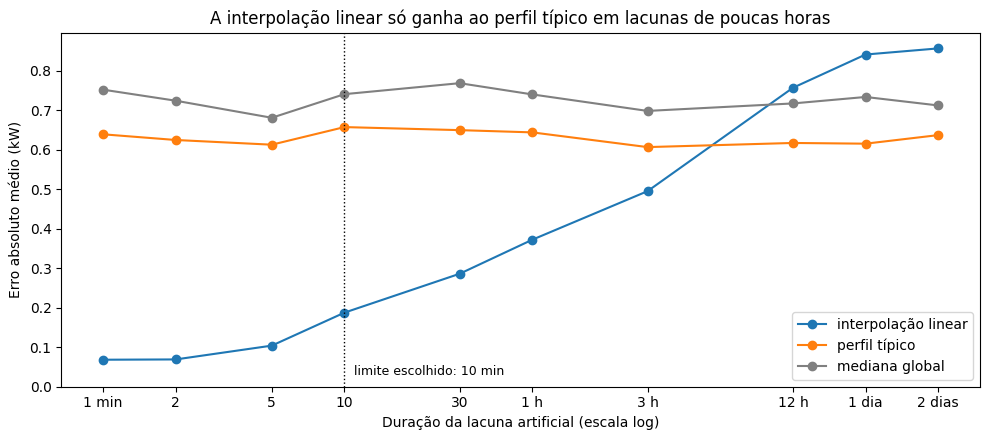

Consumo médio na janela: 1.05 kW


In [13]:
# e) Erro de reconstrução por duração da lacuna

def erro_reconstrucao(serie, duracoes, n=500, seed=SEED):
    rng = np.random.default_rng(seed)
    x = serie.to_numpy('float64')
    perfil = serie.groupby([serie.index.dayofweek, serie.index.hour]).transform('mean').to_numpy('float64')
    mediana = np.nanmedian(x)
    observado = pd.Series(serie.notna().to_numpy(dtype=float))
    linhas = []
    for L in duracoes:
        # inícios s possíveis: o troço [s-1, s+L] está todo observado
        inicios = np.flatnonzero(observado.rolling(L + 2).min().to_numpy() == 1) - L
        s = rng.choice(inicios, n, replace=False)
        pos = s[:, None] + np.arange(L)
        antes, depois = x[s - 1], x[s + L]
        interpolado = antes[:, None] + np.arange(1, L + 1) / (L + 1) * (depois - antes)[:, None]
        linhas.append({'duracao_min': L,
                       'interpolacao_linear': np.abs(interpolado - x[pos]).mean(),
                       'perfil_tipico': np.abs(perfil[pos] - x[pos]).mean(),
                       'mediana_global': np.abs(mediana - x[pos]).mean()})
    return pd.DataFrame(linhas).set_index('duracao_min')

erros = erro_reconstrucao(potencia, [1, 2, 5, 10, 30, 60, 180, 720, 1440, 2880])
display(erros.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
nomes = ['interpolação linear', 'perfil típico', 'mediana global']
for coluna, nome, cor in zip(erros.columns, nomes, ['tab:blue', 'tab:orange', 'gray']):
    ax.plot(erros.index, erros[coluna], marker='o', color=cor, label=nome)
ax.axvline(10, color='black', ls=':', lw=1)
ax.text(11, 0.03, 'limite escolhido: 10 min', fontsize=9)
ax.set_xscale('log')
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xticks(erros.index, ['1 min', '2', '5', '10', '30', '1 h', '3 h', '12 h', '1 dia', '2 dias'])
ax.set_ylim(0, None)
ax.set_xlabel('Duração da lacuna artificial (escala log)')
ax.set_ylabel('Erro absoluto médio (kW)')
ax.set_title('A interpolação linear só ganha ao perfil típico em lacunas de poucas horas')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Consumo médio na janela: {potencia.mean():.2f} kW')

R.: Até 10 minutos, a interpolação linear erra em média entre 0,07 e 0,19 kW por minuto, três a nove vezes menos do que o perfil típico (cerca de 0,63 kW), porque o consumo ao minuto muda devagar. A vantagem encolhe com a duração e desaparece entre 3 e 12 horas. Numa lacuna de 2 dias, a reta entre os dois extremos erra 0,86 kW, pior até do que usar sempre a mediana (0,71 kW). O perfil típico também não serve para 2 dias: erra cerca de 0,64 kW por minuto, 60 % do consumo médio, e assume que a casa estava ocupada, o que a hipótese MNAR põe em causa.

A decisão, por duração da lacuna:

| Lacuna | Na janela | Decisão | Porquê |
|---|---|---|---|
| 1 a 10 min | 20 lacunas, 36 min | interpolação linear no tempo | erro ≤ 0,19 kW; no pior caso preenche 1/6 da janela de 60 min da Parte IV, por isso não chega para fabricar um padrão |
| 11 min a 1 dia | 4 lacunas, 175 min | ficam NaN ao minuto; nos agregados entram só os minutos observados | uma reta de 1 h já esconde os ciclos dos aparelhos e falsearia variâncias e alarmes na Parte IV |
| mais de 1 dia | 1 lacuna, 3 305 min | não se imputa; os dias com menos de 90 % de cobertura saem das análises diárias | não há informação para reconstruir: mesmo o perfil típico erra cerca de 60 % do consumo médio, e o mecanismo pode ser MNAR |

A regra dos 90 % de cobertura aplica-se a todos os dias, qualquer que seja a lacuna; na nossa janela só os três dias da falha longa ficam abaixo (ver a aplicação a seguir).

O limite de 10 minutos é conservador: pelo teste, a interpolação continua a ganhar ao perfil até cerca de 3 horas, mas para a Parte IV interessa-nos não introduzir troços artificiais longos ao minuto.

In [14]:
# e) Aplicação

limpo = tratar_lacunas(df, max_minutos=10)
diario = consumo_diario(limpo, cobertura_min=0.9)

print(f"Minutos interpolados: {df['Global_active_power'].isna().sum() - limpo['Global_active_power'].isna().sum()}")
print(f"Minutos que ficam em falta: {limpo['Global_active_power'].isna().sum()}")
print(f"Dias válidos para análise diária: {diario['kWh'].notna().sum()} de {len(diario)}")
diario[diario['cobertura'] < 1].sort_values('cobertura').round(3)

Minutos interpolados: 36
Minutos que ficam em falta: 3480
Dias válidos para análise diária: 544 de 547


,kWh,cobertura
instante,,
2009-06-14,NaN,0.000
2009-06-13,NaN,0.021
2009-06-15,NaN,0.684
2008-12-10,36.981,0.951
2008-10-25,26.167,0.970
2009-02-01,30.941,0.974
2009-02-17,13.249,0.983


R.: A regra interpola 36 minutos, deixa 3 480 em falta e tira 3 dias das análises diárias (13, 14 e 15 de junho de 2009), ficando 544 de 547. O limiar de 90 % não é crítico: o dia mais incompleto que fica (10/12/2008, com a lacuna de 70 min) tem 95 % de cobertura e o mais completo que sai (15/06/2009) tem 68 %, por isso qualquer limiar entre 70 % e 95 % dá o mesmo resultado. Tirar o dia 15 também evita um enviesamento: as horas que lhe faltam são a madrugada (00:00 a 07:34), quando o consumo é baixo, e a média dos minutos observados sobrestimaria o consumo desse dia. Na Parte III, os lags que dependam destes dias ficam NaN em vez de serem inventados.

# Resumo para o Checkpoint 1

- **Dados:** 2 075 259 minutos carregados em menos de meio minuto, com tipos explícitos; janela do grupo de 01/02/2008 a 31/07/2009 (787 680 minutos).
- **Tipagem:** dicionário de dados com escala de Stevens; float32 justificado; 10 asserts, testados contra 5 versões estragadas dos dados.
- **Qualidade:** 0,45 % dos minutos em falta, sempre a linha inteira; 25 lacunas, uma delas (2,3 dias) com 94 % dos minutos em falta; 1 dia inteiro sem leituras.
- **Tratamento:** três regimes por duração da lacuna, com o limite de 10 min apoiado num teste de reconstrução.
- **Em aberto para o CP2:** sumário e outliers (1.3); confirmar o indício de falhas em picos de carga nas lacunas fora da nossa janela; decidir como tratar o possível desfasamento de hora de verão nos perfis horários.